<a href="https://colab.research.google.com/github/caroline-reges/Image-Identification-Using-Deep-Learning/blob/main/Deep%20Learning%20Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import packages

In [16]:
#keeps google colab connected to my drive
from google.colab import drive
drive.mount('/content/drive')

import os #use to navigate folders

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files #used for saving files
from PIL import Image, ImageOps #used to look at image dimensions

import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, datasets
from tensorflow.keras.layers import GlobalMaxPooling2D




Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Load Data

In [2]:
images_path = "/content/drive/MyDrive/animals10/raw-img"

print(os.listdir(images_path))

['horse', 'sheep', 'dog', 'elephant', 'butterfly', 'chicken', 'cat', 'cow', 'spider', 'squirrel']


# Data cleaning and EDA, Data Preprocessing

Change my folder names from italian to english

In [ ]:
translate = {"cane": "dog", "cavallo": "horse", "elefante": "elephant", "farfalla": "butterfly",
             "gallina": "chicken", "gatto": "cat", "mucca": "cow", "pecora": "sheep",
             "ragno": "spider", "scoiattolo": "squirrel"}
for italian, english in translate.items():
    old_path = os.path.join(images_path, italian) #create old folder path
    new_path = os.path.join(images_path, english) #create new folder path

    if os.path.exists(old_path): #I can run this code again and it won't give me errors
        os.rename(old_path, new_path) #rename folder


Check class distribution

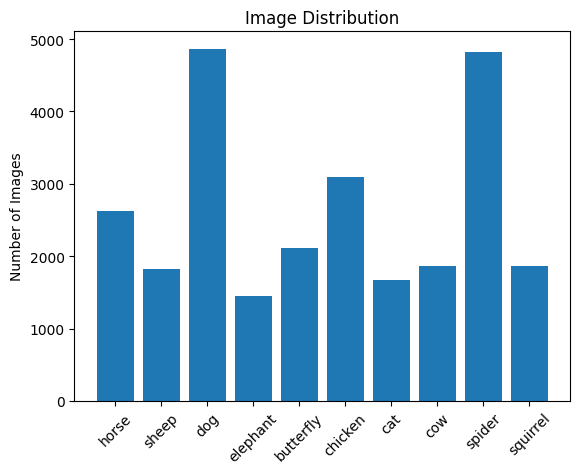

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
image_count = []

for folder in os.listdir(images_path):
  #count number of images in each folder
  folder_path = os.path.join(images_path, folder)
  num_images = len(os.listdir(folder_path))

  image_count.append((folder, num_images))

dist_df = pd.DataFrame(image_count, columns=['Folder', 'Count'])

plt.bar(dist_df['Folder'], dist_df['Count'])
plt.title('Image Distribution')
plt.ylabel('Number of Images')
plt.xticks(rotation=45)

plt.savefig('image_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

#files.download('image_distribution.png')

Look at image dimensions in the dog folder

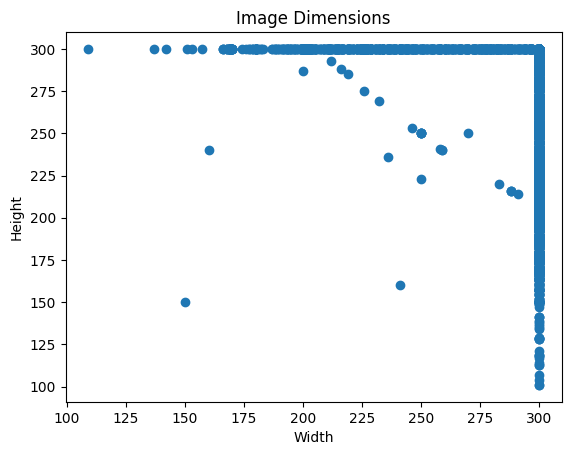

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
folder_path = os.path.join(images_path, 'dog')

image_dimensions = []

for file in os.listdir(folder_path):
    image_path = os.path.join(folder_path, file)

    with Image.open(image_path) as img:
        width, height = img.size

    image_dimensions.append((file, width, height))

dim_df = pd.DataFrame(image_dimensions, columns=['File', 'Width', 'Height'])

plt.scatter(dim_df['Width'], dim_df['Height'])
plt.title('Image Dimensions')
plt.xlabel('Width')
plt.ylabel('Height')

plt.savefig('image_size_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

files.download('image_size_distribution.png')

Check for corrupt images

In [ ]:
for folder in os.listdir(images_path):
  folder_path = os.path.join(images_path, folder)

  for file in os.listdir(folder_path):
        image_path = os.path.join(folder_path, file)

        try: #use this because we know there may be errors
            with Image.open(image_path) as img:
                img.verify()
        except Exception:
            print("Corrupted image:", image_path)

Check how many images have different color formats

In [ ]:
color_counts = {}

for folder in os.listdir(images_path):
    folder_path = os.path.join(images_path, folder)

    for file in os.listdir(folder_path):
        image_path = os.path.join(folder_path, file)

        with Image.open(image_path) as img:
            mode = img.mode
            color_counts[mode] = color_counts.get(mode, 0) + 1

print(color_counts)


#delete the images that are not RGB
for folder in os.listdir(images_path):
    folder_path = os.path.join(images_path, folder)

    for file in os.listdir(folder_path):
        image_path = os.path.join(folder_path, file)

        with Image.open(image_path) as img:
            if img.mode != "RGB":
                print("Non-RGB:", image_path)
                #os.remove(image_path)

{'RGB': 26128, 'RGBA': 49, 'CMYK': 1, 'L': 1}
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/ea35b80a2df1033ed1584d05fb1d4e9fe777ead218ac104497f5c978a4efb4bb_640.png
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/ea35b80a2df1053ed1584d05fb1d4e9fe777ead218ac104497f5c978a4efb4bb_640.png
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/ea34b10b21f5083ed1584d05fb1d4e9fe777ead218ac104497f5c978a4efb4bb_640.jpg
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/e835b50620f7083ed1584d05fb1d4e9fe777ead218ac104497f5c978a4eebdbd_640.png
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/ea35b80a2df1043ed1584d05fb1d4e9fe777ead218ac104497f5c978a4efb4bb_640.png
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/e83db7072afd013ed1584d05fb1d4e9fe777ead218ac104497f5c978a4eebdbd_640.jpg
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/e835b50620f7093ed1584d05fb1d4e9fe777ead218ac104497f5c978a4eebdbd_640.png
Non-RGB: /content/drive/MyDriv

### Note to self: Run this every time I reopen my code

Load images and labels. Resize images by changing the pixel dimensions to 128x128 (may adjust later). Divide into training and test sets.

In [17]:
images = []
labels = []

folders = sorted(os.listdir(images_path))

for label, folder in enumerate(folders):
    folder_path = os.path.join(images_path, folder)

    for file in os.listdir(folder_path):
        image_path = os.path.join(folder_path, file)

        with Image.open(image_path) as img:
            #resize to 128 x 128, but keep original image proportions
            img = ImageOps.pad(img, (128, 128),
                               method=Image.Resampling.LANCZOS,
                               color=(0, 0, 0))
            images.append(np.array(img))

        labels.append(label)

#Convert to numpy arrays immediately after loading
images = np.array(images)
labels = np.array(labels)

#Divide the data into training and test sets
x_train, x_test, y_train, y_test = train_test_split(
    images,
    labels,
    test_size=0.2,
    random_state=1,
    stratify=labels
    #stratify keeps the same proportion of training and test images
    #within each label
)

#scale the images from 0-255 to 0-1
x_train, x_test = x_train / 255.0, x_test / 255.0

#one hot encode the categories
num_classes = 10
y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test  = tf.keras.utils.to_categorical(y_test , num_classes)

# First Model - Simple CNN

Build an initial simple CNN

In [18]:
model = models.Sequential([

    layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(128,128,3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.Flatten(),

    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │     4,194,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,251,338 (16.22 MB)

 Trainable params: 4,251,338 (16.22 MB)

 Non-trainable params: 0 (0.00 B)

Compile and train model
Calculate test accuracy, and predict on unseen images

Epoch 1/15
262/262 - 17s - 66ms/step - accuracy: 0.2914 - loss: 1.9998 - val_accuracy: 0.3755 - val_loss: 1.7910
Epoch 2/15
262/262 - 9s - 36ms/step - accuracy: 0.4633 - loss: 1.5610 - val_accuracy: 0.4697 - val_loss: 1.5452
Epoch 3/15
262/262 - 9s - 36ms/step - accuracy: 0.5455 - loss: 1.3270 - val_accuracy: 0.5460 - val_loss: 1.3438
Epoch 4/15
262/262 - 9s - 36ms/step - accuracy: 0.6171 - loss: 1.1453 - val_accuracy: 0.5578 - val_loss: 1.3093
Epoch 5/15
262/262 - 9s - 36ms/step - accuracy: 0.6639 - loss: 0.9835 - val_accuracy: 0.5807 - val_loss: 1.2796
Epoch 6/15
262/262 - 9s - 35ms/step - accuracy: 0.7294 - loss: 0.7961 - val_accuracy: 0.5790 - val_loss: 1.3904
Epoch 7/15
262/262 - 9s - 35ms/step - accuracy: 0.7976 - loss: 0.6022 - val_accuracy: 0.5958 - val_loss: 1.4100
Epoch 8/15
262/262 - 9s - 35ms/step - accuracy: 0.8688 - loss: 0.4021 - val_accuracy: 0.5860 - val_loss: 1.6342
Epoch 9/15
262/262 - 9s - 35ms/step - accuracy: 0.9160 - loss: 0.2647 - val_accuracy: 0.5889 - val_loss

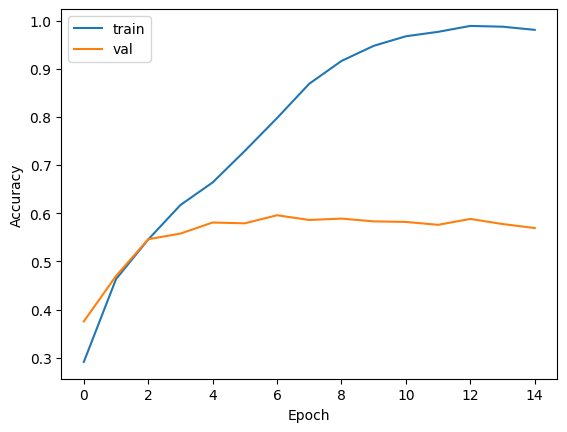

In [19]:
#compile and train model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train,
                    epochs=15,
                    batch_size=64,
                    validation_split=0.2,
                    verbose=2)

#calculate test accuracy, and predict on unseen images
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print(f"Test accuracy = {test_acc:.3f}")

predictions = model.predict(x_test)

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()

# Simple CNN Hyperparameter Tuning

Find an alternative to flatten. Try max pooling instead.

In [24]:
model = models.Sequential([

    layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(128,128,3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),

    GlobalMaxPooling2D(), #removed flatten, replaced it with this

    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d_7          │ (None, 64)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,130 (238.79 KB)

 Trainable params: 61,130 (238.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
262/262 - 16s - 60ms/step - accuracy: 0.2807 - loss: 2.0481 - val_accuracy: 0.3999 - val_loss: 1.7586
Epoch 2/15
262/262 - 9s - 34ms/step - accuracy: 0.4442 - loss: 1.6259 - val_accuracy: 0.4497 - val_loss: 1.5794
Epoch 3/15
262/262 - 9s - 34ms/step - accuracy: 0.4969 - loss: 1.4649 - val_accuracy: 0.5408 - val_loss: 1.3764
Epoch 4/15
262/262 - 9s - 35ms/step - accuracy: 0.5412 - loss: 1.3465 - val_accuracy: 0.5492 - val_loss: 1.3331
Epoch 5/15
262/262 - 9s - 34ms/step - accuracy: 0.5710 - loss: 1.2662 - val_accuracy: 0.5630 - val_loss: 1.2699
Epoch 6/15
262/262 - 9s - 34ms/step - accuracy: 0.5915 - loss: 1.1932 - val_accuracy: 0.5805 - val_loss: 1.2331
Epoch 7/15
262/262 - 9s - 34ms/step - accuracy: 0.6077 - loss: 1.1428 - val_accuracy: 0.5786 - val_loss: 1.2098
Epoch 8/15
262/262 - 9s - 34ms/step - accuracy: 0.6327 - loss: 1.0806 - val_accuracy: 0.5893 - val_loss: 1.1868
Epoch 9/15
262/262 - 9s - 34ms/step - accuracy: 0.6450 - loss: 1.0452 - val_accuracy: 0.6171 - val_loss

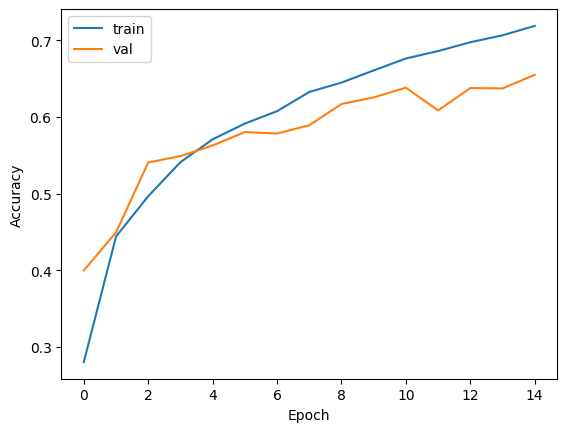

In [21]:
#compile and train model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train,
                    epochs=15,
                    batch_size=64,
                    validation_split=0.2,
                    verbose=2)

#calculate test accuracy, and predict on unseen images
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print(f"Test accuracy = {test_acc:.3f}")

predictions = model.predict(x_test)

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()

Run the same model again but with more epochs

Epoch 1/30
262/262 - 16s - 60ms/step - accuracy: 0.3018 - loss: 1.9983 - val_accuracy: 0.3798 - val_loss: 1.8328
Epoch 2/30
262/262 - 9s - 34ms/step - accuracy: 0.4401 - loss: 1.6328 - val_accuracy: 0.4659 - val_loss: 1.5475
Epoch 3/30
262/262 - 9s - 35ms/step - accuracy: 0.4942 - loss: 1.4785 - val_accuracy: 0.4961 - val_loss: 1.4747
Epoch 4/30
262/262 - 9s - 35ms/step - accuracy: 0.5277 - loss: 1.3863 - val_accuracy: 0.5092 - val_loss: 1.4428
Epoch 5/30
262/262 - 9s - 35ms/step - accuracy: 0.5570 - loss: 1.3097 - val_accuracy: 0.5590 - val_loss: 1.2888
Epoch 6/30
262/262 - 9s - 34ms/step - accuracy: 0.5793 - loss: 1.2381 - val_accuracy: 0.5740 - val_loss: 1.2535
Epoch 7/30
262/262 - 9s - 34ms/step - accuracy: 0.5943 - loss: 1.1842 - val_accuracy: 0.5790 - val_loss: 1.2361
Epoch 8/30
262/262 - 9s - 34ms/step - accuracy: 0.6132 - loss: 1.1354 - val_accuracy: 0.5747 - val_loss: 1.2270
Epoch 9/30
262/262 - 9s - 34ms/step - accuracy: 0.6195 - loss: 1.0986 - val_accuracy: 0.6049 - val_loss

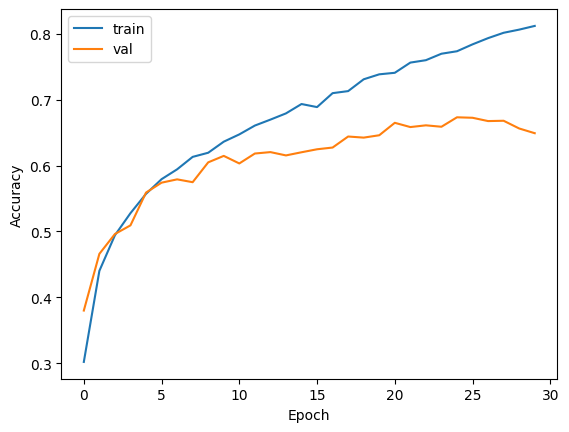

In [25]:
#compile and train model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train,
                    epochs=30,
                    batch_size=64,
                    validation_split=0.2,
                    verbose=2)

#calculate test accuracy, and predict on unseen images
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print(f"Test accuracy = {test_acc:.3f}")

predictions = model.predict(x_test)

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()

Add a augmentation layer to the model

In [ ]:
model = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    # Data augmentation
    layers.RandomFlip("horizontal"),

    layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),

    GlobalMaxPooling2D(), #removed flatten, replaced it with this

    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()

In [ ]:
#compile and train model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train,
                    epochs=15,
                    batch_size=64,
                    validation_split=0.2,
                    verbose=2)

#calculate test accuracy, and predict on unseen images
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print(f"Test accuracy = {test_acc:.3f}")

predictions = model.predict(x_test)

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()